# Preprocessing

In [1]:
!pip install ultralytics -q

import os
import shutil
import random
from pathlib import Path
import cv2
import yaml

# Tắt W&B để không bị hỏi API key khi train trên Kaggle
os.environ["WANDB_DISABLED"] = "true"

# Tạo sẵn các thư mục đầu ra theo đúng yêu cầu dự án
Path("model").mkdir(parents=True, exist_ok=True)
Path("assets/results").mkdir(parents=True, exist_ok=True)

# Hàm tiền xử lý của Người 1 để làm sạch bbox và chia dataset
def process_and_split_dataset(source_dir, output_dir, classes, split_ratio=(0.8, 0.1, 0.1)):
    assert sum(split_ratio) == 1.0, "Tổng tỉ lệ chia phải bằng 1.0"
    src_path, out_path = Path(source_dir), Path(output_dir)
    
    if out_path.exists():
        shutil.rmtree(out_path)

    img_src_dir, lbl_src_dir = src_path / 'images', src_path / 'labels'
    for split in ['train', 'val', 'test']:
        (out_path / split / 'images').mkdir(parents=True, exist_ok=True)
        (out_path / split / 'labels').mkdir(parents=True, exist_ok=True)

    print("Đang quét và bắt cặp dữ liệu...")
    img_paths = []
    for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
        img_paths.extend(img_src_dir.rglob(ext))

    labels_dict = {p.stem: p for p in lbl_src_dir.rglob('*.txt')}
    valid_data, fixed_count, removed_count = [], 0, 0

    for img_path in img_paths:
        stem = img_path.stem
        lbl_path = labels_dict.get(stem)
        img = cv2.imread(str(img_path))
        if img is None:
            removed_count += 1
            continue

        clean_lines = []
        if lbl_path and lbl_path.exists():
            with open(lbl_path, 'r') as f:
                lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) != 5: continue
                try:
                    class_id = int(parts[0])
                    x_c, y_c, w, h = map(float, parts[1:])
                except ValueError:
                    continue

                if class_id < 0 or class_id >= len(classes) or w <= 0 or h <= 0 or x_c > 2.0 or y_c > 2.0:
                    continue

                x_min, y_min = max(0.0, x_c - w/2), max(0.0, y_c - h/2)
                x_max, y_max = min(1.0, x_c + w/2), min(1.0, y_c + h/2)
                new_w, new_h = x_max - x_min, y_max - y_min
                new_xc, new_yc = x_min + new_w/2, y_min + new_h/2

                if round(new_w, 4) != round(w, 4) or round(new_h, 4) != round(h, 4):
                    fixed_count += 1

                clean_lines.append(f"{class_id} {new_xc:.6f} {new_yc:.6f} {new_w:.6f} {new_h:.6f}\n")

        if clean_lines:
            valid_data.append({'img_path': img_path, 'clean_lines': clean_lines})
        else:
            removed_count += 1

    print(f"Làm sạch xong! Hợp lệ: {len(valid_data)}, Sửa bbox: {fixed_count}, Loại bỏ: {removed_count}")

    random.seed(42)
    random.shuffle(valid_data)
    total = len(valid_data)
    train_end = int(total * split_ratio[0])
    val_end = train_end + int(total * split_ratio[1])

    splits_data = {
        'train': valid_data[:train_end],
        'val': valid_data[train_end:val_end],
        'test': valid_data[val_end:]
    }

    for split_name, data_list in splits_data.items():
        for data in data_list:
            img_p = data['img_path']
            shutil.copy(img_p, out_path / split_name / 'images' / img_p.name)
            with open(out_path / split_name / 'labels' / f"{img_p.stem}.txt", 'w') as f:
                f.writelines(data['clean_lines'])

    yaml_content = {
        'path': str(out_path.absolute()),
        'train': 'train/images',
        'val': 'val/images',
        'test': 'test/images',
        'names': {i: name for i, name in enumerate(classes)}
    }
    with open(out_path / 'data.yaml', 'w') as f:
        yaml.dump(yaml_content, f, default_flow_style=False, sort_keys=False)
    print(f"Đã lưu dataset sạch tại: {out_path.absolute()}")

# Chạy tiền xử lý tự động tìm đường dẫn trên Kaggle
SOURCE_DIR = list(Path("/kaggle/input").rglob("pcb_yolo_cropped"))[0]
OUTPUT_DIR = "./pcb_dataset_cleaned"
CLASSES = ['resistor', 'capacitor', 'connector', 'ic', 'led', 'diode', 'transistor', 'inductor', 'jumper', 'button']
process_and_split_dataset(SOURCE_DIR, OUTPUT_DIR, CLASSES, split_ratio=(0.8, 0.1, 0.1))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 954.2 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 5.2 MB/s eta 0:00:00
Đang quét và bắt cặp dữ liệu...
Làm sạch xong! Hợp lệ: 460, Sửa bbox: 92, Loại bỏ: 0
Đã lưu dataset sạch tại: /kaggle/working/pcb_dataset_cleaned


# 1. Kiểm tra dataset đầu vào

=== 4.1. KIỂM TRA DATASET ===
Số lượng class: 10
Danh sách class: ['resistor', 'capacitor', 'connector', 'ic', 'led', 'diode', 'transistor', 'inductor', 'jumper', 'button']

Tập TRAIN: 368 ảnh | 368 nhãn
Tập VAL  : 46 ảnh | 46 nhãn
Tập TEST : 46 ảnh | 46 nhãn


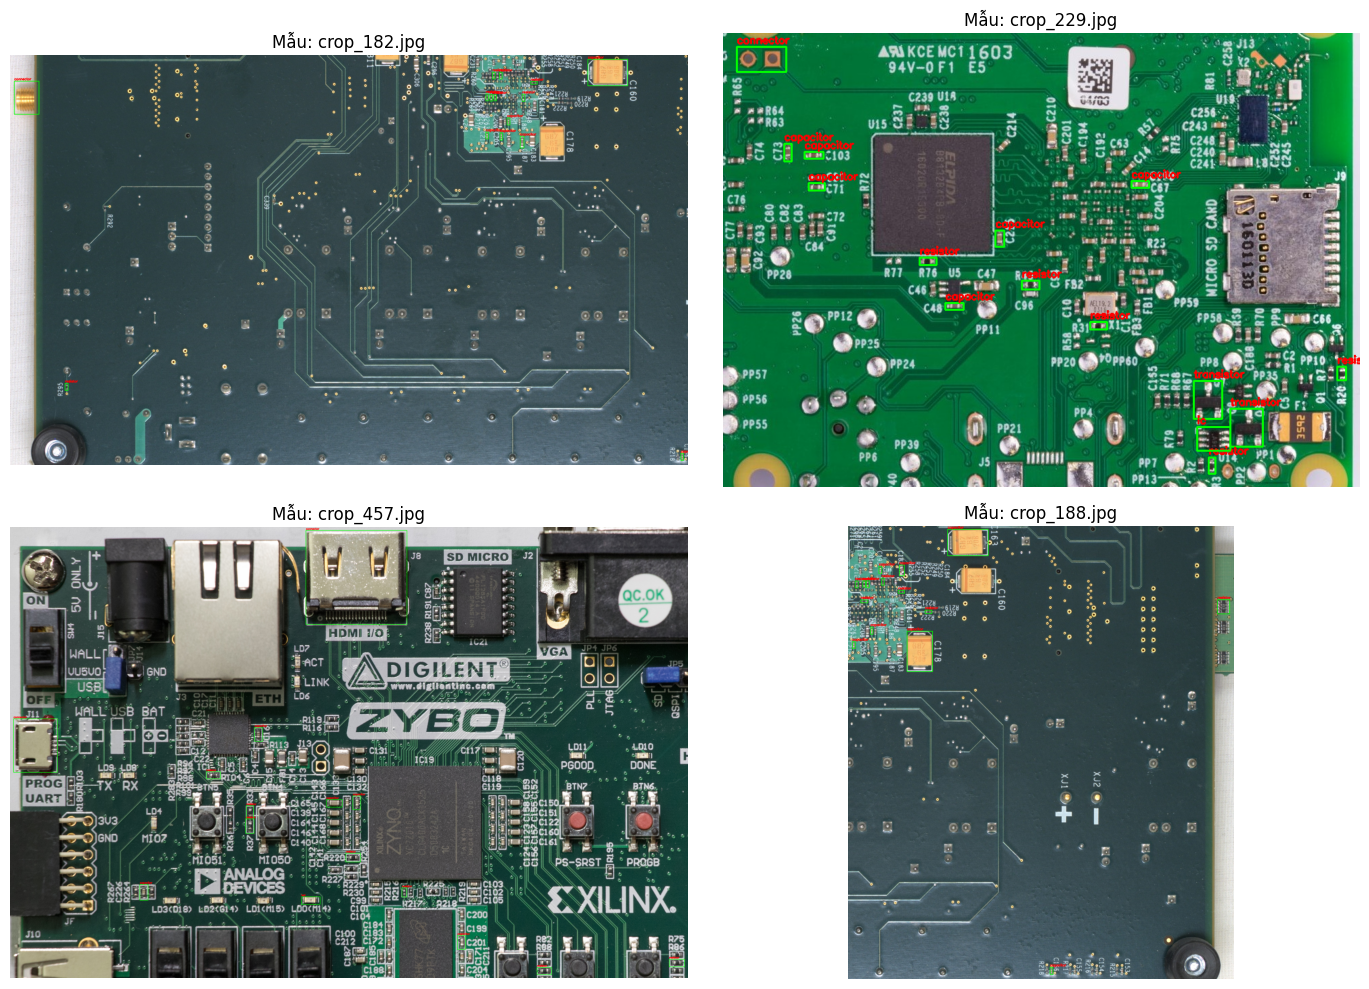

In [2]:
import yaml
import cv2
import random
import matplotlib.pyplot as plt

dataset_path = Path("./pcb_dataset_cleaned")
yaml_file = dataset_path / "data.yaml"

with open(yaml_file, 'r') as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg['names']
print("=== 4.1. KIỂM TRA DATASET ===")
print(f"Số lượng class: {len(class_names)}")
print(f"Danh sách class: {list(class_names.values())}\n")

for split in ['train', 'val', 'test']:
    imgs = list((dataset_path / split / 'images').glob('*.*'))
    lbls = list((dataset_path / split / 'labels').glob('*.txt'))
    print(f"Tập {split.upper():5s}: {len(imgs)} ảnh | {len(lbls)} nhãn")

# Trực quan hóa bounding box mẫu
sample_imgs = random.sample(list((dataset_path / 'train' / 'images').glob('*.*')), 4)
plt.figure(figsize=(14, 10))
for idx, img_p in enumerate(sample_imgs):
    img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)
    h_img, w_img, _ = img.shape
    lbl_p = dataset_path / 'train' / 'labels' / f"{img_p.stem}.txt"
    if lbl_p.exists():
        with open(lbl_p, 'r') as f:
            for line in f:
                cls_id, xc, yc, w, h = map(float, line.strip().split())
                x1, y1 = int((xc - w/2) * w_img), int((yc - h/2) * h_img)
                x2, y2 = int((xc + w/2) * w_img), int((yc + h/2) * h_img)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(img, class_names[int(cls_id)], (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    plt.subplot(2, 2, idx + 1)
    plt.imshow(img)
    plt.title(f"Mẫu: {img_p.name}")
    plt.axis('off')
plt.tight_layout()
plt.savefig("assets/results/sample_ground_truth.png", dpi=150)
plt.show()

# 2. Xây dựng model và train model

In [3]:
from ultralytics import YOLO
import pandas as pd

# Khởi tạo mô hình với Pretrained Weights
model = YOLO('yolo26n.pt')

# Bắt đầu huấn luyện với dataset PCB đã làm sạch
results = model.train(
    data='./pcb_dataset_cleaned/data.yaml',
    epochs=100,
    patience=20,
    batch=16,
    imgsz=640,
    optimizer='AdamW',
    lr0=0.001,
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.3,
    degrees=90.0,
    flipud=0.5,
    fliplr=0.5,
    device=0,
    workers=4,
    project='PCB_Detection',
    name='yolo26n_train',
    exist_ok=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./pcb_dataset_cleaned/data.yaml, degrees=90.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      2.86G      2.246      3.882   0.007192        494        640: 100% ━━━━━━━━━━━━ 23/23 4.0it/s 5.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.7it/s 0.7s1.5s
                   all         46        662    0.00992     0.0731    0.00438    0.00224

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/100      2.86G      2.191      3.575   0.007048        384        640: 100% ━━━━━━━━━━━━ 23/23 3.7it/s 6.3s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s1.4s
                   all         46        662      0.149     0.0708     0.0365     0.0174

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/100      2.86G      2.144      3.424   0.007012        378        640: 100% ━━━━━━━━━━━━ 23/23 3.2it/s 7.1s0.3s
                 Class     Images  Instances  

In [4]:
import shutil
from pathlib import Path

# Tạo thư mục model/ và assets/results/ nếu chưa có
Path("model").mkdir(parents=True, exist_ok=True)
Path("assets/results").mkdir(parents=True, exist_ok=True)

# Copy file best.pt từ thư mục runs/detect sang thư mục model/
src = Path("/kaggle/working/runs/detect/PCB_Detection/yolo26n_train/weights/best.pt")
dst = Path("model/best.pt")

if src.exists():
    shutil.copy(src, dst)
    print(f"Đã lưu model tốt nhất thành công tại: {dst.resolve()}")
else:
    print("Không tìm thấy file nguồn.")

Đã lưu model tốt nhất thành công tại: /kaggle/working/model/best.pt


# 3. Training curve & Metric analysis

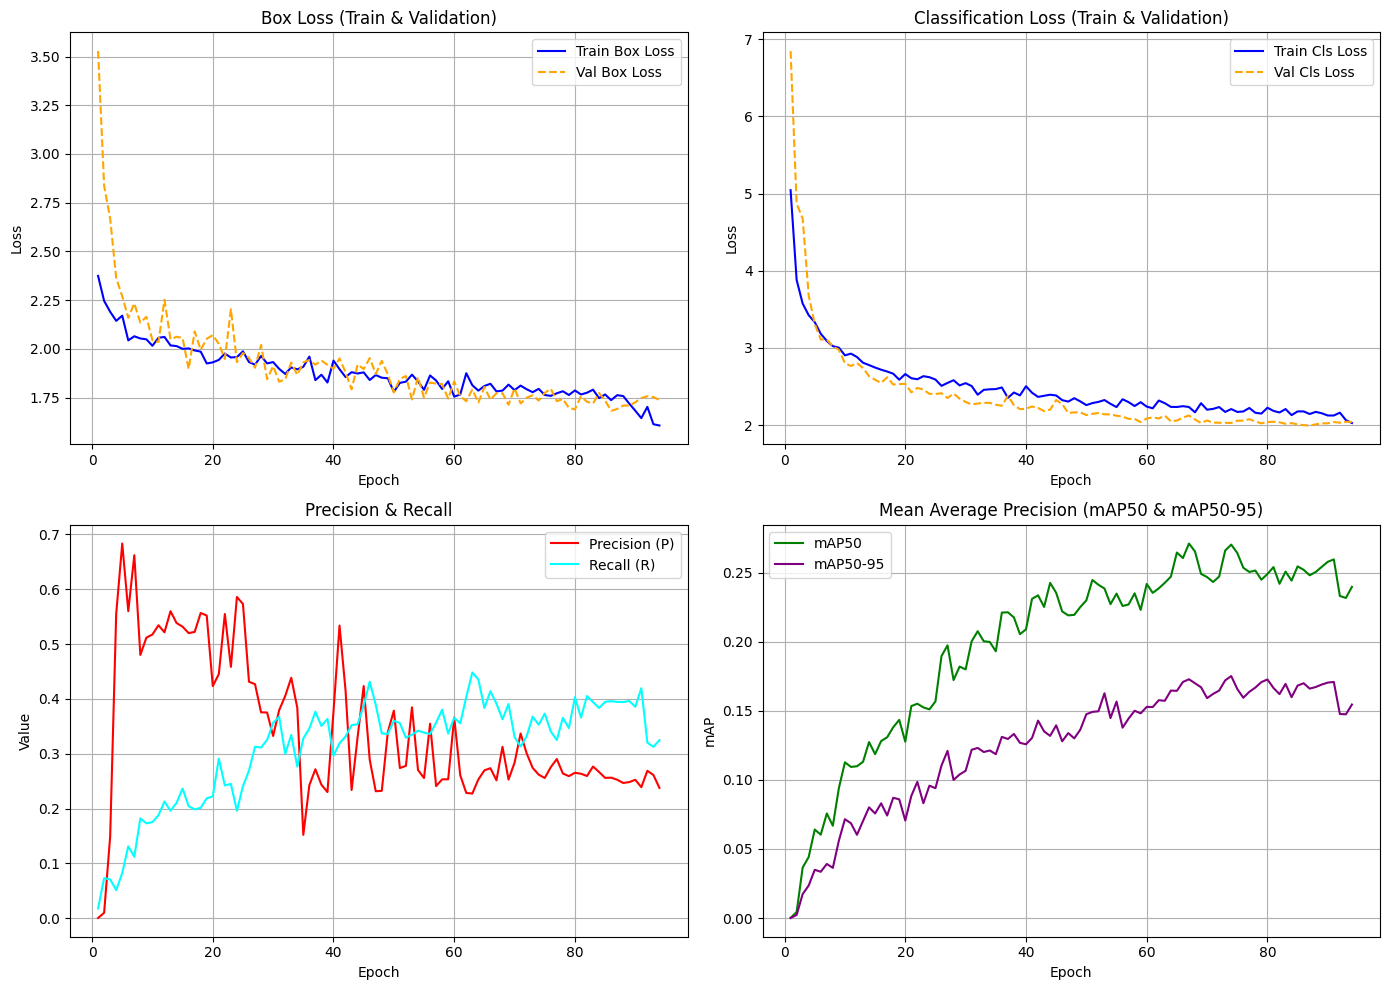

Đã vẽ và lưu biểu đồ theo dõi toàn bộ các chỉ số tại: assets/results/comprehensive_training_metrics.png


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Tìm đường dẫn đến file kết quả huấn luyện
run_dirs = list(Path("runs/detect").rglob("yolo26n_train"))
if run_dirs:
    results_csv = run_dirs[0] / "results.csv"
    if results_csv.exists():
        df = pd.read_csv(results_csv)
        df.columns = df.columns.str.strip()

        # Tạo khung gồm 4 đồ thị để theo dõi toàn diện các chỉ số
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        # 1. Box Loss (Train vs Validation)
        axes[0, 0].plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', color='blue')
        axes[0, 0].plot(df['epoch'], df['val/box_loss'], label='Val Box Loss', color='orange', linestyle='--')
        axes[0, 0].set_title('Box Loss (Train & Validation)')
        axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
        axes[0, 0].legend(); axes[0, 0].grid(True)

        # 2. Classification Loss (Train vs Validation) [nếu có trong log]
        if 'train/cls_loss' in df.columns and 'val/cls_loss' in df.columns:
            axes[0, 1].plot(df['epoch'], df['train/cls_loss'], label='Train Cls Loss', color='blue')
            axes[0, 1].plot(df['epoch'], df['val/cls_loss'], label='Val Cls Loss', color='orange', linestyle='--')
            axes[0, 1].set_title('Classification Loss (Train & Validation)')
            axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Loss')
            axes[0, 1].legend(); axes[0, 1].grid(True)

        # 3. Precision & Recall
        if 'metrics/precision(B)' in df.columns and 'metrics/recall(B)' in df.columns:
            axes[1, 0].plot(df['epoch'], df['metrics/precision(B)'], label='Precision (P)', color='red')
            axes[1, 0].plot(df['epoch'], df['metrics/recall(B)'], label='Recall (R)', color='cyan')
            axes[1, 0].set_title('Precision & Recall')
            axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Value')
            axes[1, 0].legend(); axes[1, 0].grid(True)

        # 4. mAP50 & mAP50-95
        if 'metrics/mAP50(B)' in df.columns and 'metrics/mAP50-95(B)' in df.columns:
            axes[1, 1].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50', color='green')
            axes[1, 1].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95', color='purple')
            axes[1, 1].set_title('Mean Average Precision (mAP50 & mAP50-95)')
            axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('mAP')
            axes[1, 1].legend(); axes[1, 1].grid(True)

        plt.tight_layout()
        plt.savefig("assets/results/comprehensive_training_metrics.png", dpi=150)
        plt.show()
        print("Đã vẽ và lưu biểu đồ theo dõi toàn bộ các chỉ số tại: assets/results/comprehensive_training_metrics.png")

# 4. Đánh giá & Trực quan hóa

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,391,922 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4123.5±1176.6 MB/s, size: 1291.5 KB)
val: Scanning /kaggle/working/pcb_dataset_cleaned/test/labels... 46 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 46/46 1.2Kit/s 0.0s
val: New cache created: /kaggle/working/pcb_dataset_cleaned/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2it/s 2.4s1.6s
                   all         46        670      0.236      0.374      0.281      0.197
              resistor         44        199      0.376      0.347      0.309      0.189
             capacitor         41        202       0.22      0.267      0.167      0.102
             connector         33        101      0.366      0.723      0.572      0.304
                    ic         29         7

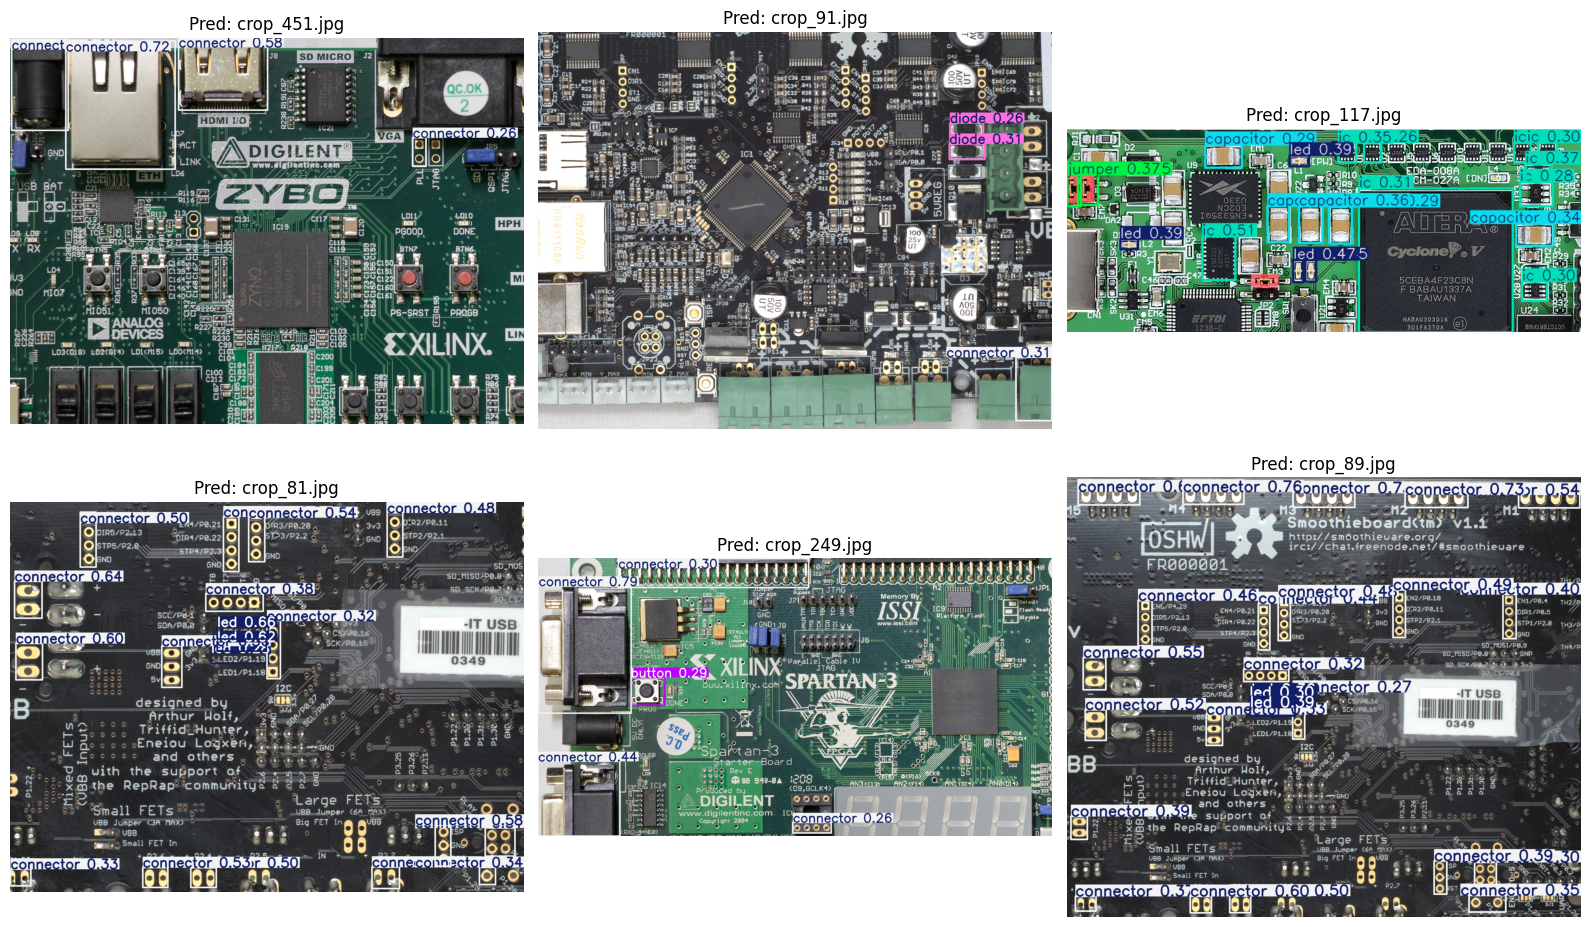

In [7]:
best_model = YOLO('model/best.pt')

val_metrics = best_model.val(
    data=str(yaml_file),
    split='test',
    project='PCB_Detection',
    name='yolo26n_eval_test',
    exist_ok=True
)

print("\n=== 4.4. KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ===")
print(f"- Precision : {val_metrics.box.mp:.4f}")
print(f"- Recall    : {val_metrics.box.mr:.4f}")
print(f"- mAP50     : {val_metrics.box.map50:.4f}")
print(f"- mAP50-95  : {val_metrics.box.map:.4f}")

# Lưu bảng metric chi tiết
per_class_data = []
for i, cls_idx in enumerate(val_metrics.box.ap_class_index):
    per_class_data.append({
        'Class': class_names[cls_idx],
        'Precision': round(val_metrics.box.p[i], 4),
        'Recall': round(val_metrics.box.r[i], 4),
        'mAP50': round(val_metrics.box.ap50[i], 4),
        'mAP50-95': round(val_metrics.box.ap[i], 4)
    })
pd.DataFrame(per_class_data).to_csv("assets/results/evaluation_metrics.csv", index=False)

# Trực quan hóa kết quả Prediction
test_imgs = list((dataset_path / 'test' / 'images').glob('*.*'))[:6]
preds = best_model.predict(test_imgs, conf=0.25, iou=0.45)

plt.figure(figsize=(16, 10))
for i, pred in enumerate(preds):
    plotted_img = cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(plotted_img)
    plt.title(f"Pred: {Path(pred.path).name}")
    plt.axis('off')
plt.tight_layout()
plt.savefig("assets/results/test_predictions_sample.png", dpi=150)
plt.show()

In [8]:
# [Cell bổ sung] Tự động sinh và lưu khoảng 20 ảnh prediction riêng lẻ (từ prediction_01.jpg đến prediction_20.jpg)
import cv2
import shutil
from pathlib import Path
from ultralytics import YOLO

results_dir = Path("assets/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Load lại model tốt nhất (hoặc tận dụng biến best_model nếu đã chạy ở cell trên)
if 'best_model' not in locals():
    best_model = YOLO('model/best.pt')

# Lấy danh sách ảnh tập test
dataset_path = Path("./pcb_dataset_cleaned")
test_imgs_all = list((dataset_path / 'test' / 'images').glob('*.*'))
num_to_predict = min(20, len(test_imgs_all))
selected_test_imgs = test_imgs_all[:num_to_predict]

print(f"Đang sinh và lưu {num_to_predict} ảnh prediction riêng lẻ vào assets/results/...")
for idx, img_p in enumerate(selected_test_imgs, 1):
    preds_single = best_model.predict(str(img_p), conf=0.25, iou=0.45, verbose=False)
    plotted_single = preds_single[0].plot()
    
    out_file = results_dir / f"prediction_{idx:02d}.jpg"
    cv2.imwrite(str(out_file), plotted_single)

print(f"Đã lưu thành công các file từ prediction_01.jpg đến prediction_{num_to_predict:02d}.jpg vào thư mục assets/results/!")

# Tự động đồng bộ thêm confusion_matrix và training_curve từ thư mục runs nếu có
runs_dir = Path("runs/detect")
if runs_dir.exists():
    cm_files = list(runs_dir.rglob("confusion_matrix*.png"))
    if cm_files and not (results_dir / "confusion_matrix.png").exists():
        shutil.copy(cm_files[0], results_dir / "confusion_matrix.png")
        print("Đã tự động đồng bộ thêm: confusion_matrix.png")
        
    res_plots = list(runs_dir.rglob("results.png"))
    if res_plots and not (results_dir / "training_curve.png").exists():
        shutil.copy(res_plots[0], results_dir / "training_curve.png")
        print("Đã tự động đồng bộ thêm: training_curve.png")

Đang sinh và lưu 20 ảnh prediction riêng lẻ vào assets/results/...
Đã lưu thành công các file từ prediction_01.jpg đến prediction_20.jpg vào thư mục assets/results/!
Đã tự động đồng bộ thêm: confusion_matrix.png
Đã tự động đồng bộ thêm: training_curve.png


# 5. Phân tích lỗi & Lưu kết quả

In [9]:
def compute_iou(box1, box2):
    xA, yA = max(box1[0], box2[0]), max(box1[1], box2[1])
    xB, yB = min(box1[2], box2[2]), min(box1[3], box2[3])
    interArea = max(0, xB - xA) * max(0, yB - yA)
    return interArea / float((box1[2]-box1[0])*(box1[3]-box1[1]) + (box2[2]-box2[0])*(box2[3]-box2[1]) - interArea + 1e-6)

all_preds = best_model.predict(list((dataset_path / 'test' / 'images').glob('*.*')), conf=0.20, verbose=False)
missed, wrong_cls, inaccurate = 0, 0, 0

for pred in all_preds:
    img_p = Path(pred.path)
    lbl_p = dataset_path / 'test' / 'labels' / f"{img_p.stem}.txt"
    h_img, w_img, _ = cv2.imread(str(img_p)).shape
    
    gt_boxes = []
    if lbl_p.exists():
        with open(lbl_p, 'r') as f:
            for line in f:
                c, xc, yc, w, h = map(float, line.strip().split())
                gt_boxes.append({'cls': int(c), 'box': [(xc-w/2)*w_img, (yc-h/2)*h_img, (xc+w/2)*w_img, (yc+h/2)*h_img]})
                
    pred_boxes = [{'cls': int(b.cls.item()), 'box': b.xyxy[0].cpu().numpy().tolist()} for b in pred.boxes]
    
    for gt in gt_boxes:
        best_iou = max([compute_iou(gt['box'], p['box']) for p in pred_boxes], default=0)
        if best_iou < 0.1: missed += 1
        elif 0.1 <= best_iou < 0.5: inaccurate += 1

print("=== 4.5. KẾT QUẢ PHÂN TÍCH LỖI (ERROR ANALYSIS) ===")
print(f"- Số linh kiện bị bỏ sót (Missed)      : {missed}")
print(f"- Số Bounding Box định vị lệch (IoU<0.5): {inaccurate}")

=== 4.5. KẾT QUẢ PHÂN TÍCH LỖI (ERROR ANALYSIS) ===
- Số linh kiện bị bỏ sót (Missed)      : 448
- Số Bounding Box định vị lệch (IoU<0.5): 3


# Inference

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

# Tạo thư mục đích
results_dir = Path("assets/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Load model tốt nhất
model = YOLO('model/best.pt')

# Đường dẫn tập test
test_img_dir = Path("./pcb_dataset_cleaned/test/images")
test_images = list(test_img_dir.glob("*.*"))

print("Đang chạy inference và phân tích kết quả trực quan cho assets/results/...")

# 1. Lưu các ảnh prediction mẫu (tốt, khó, trực quan)
if test_images:
    sample_images = test_images[:3] # Lấy mẫu minh họa
    for idx, img_path in enumerate(sample_images, 1):
        results = model.predict(str(img_path), conf=0.25)
        res_plotted = results[0].plot() # Vẽ bounding box
        
        # Lưu vào assets/results/ theo đúng chuẩn yêu cầu
        out_file = results_dir / f"prediction_{idx:02d}.jpg"
        cv2.imwrite(str(out_file), res_plotted)
    print("Đã lưu các ảnh: prediction_01.jpg, prediction_02.jpg, prediction_03.jpg")

# 2. Xử lý lưu biểu đồ Training Curves & Confusion Matrix từ thư mục runs nếu có sẵn
runs_dir = Path("runs/detect")
if runs_dir.exists():
    # Tìm và copy Confusion Matrix
    cm_files = list(runs_dir.rglob("confusion_matrix*.png"))
    if cm_files:
        shutil.copy(cm_files[0], results_dir / "confusion_matrix.png")
        print("Đã lưu: confusion_matrix.png")
        
    # Tìm và copy Training Curves (results.png)
    res_plots = list(runs_dir.rglob("results.png"))
    if res_plots:
        shutil.copy(res_plots[0], results_dir / "training_curve.png")
        print("Đã lưu: training_curve.png")

print("\nThư mục 'assets/results/' đã được cập nhật đầy đủ các thành phần trực quan!")

Đang chạy inference và phân tích kết quả trực quan cho assets/results/...

image 1/1 /kaggle/working/pcb_dataset_cleaned/test/images/crop_451.jpg: 512x640 6 connectors, 8.2ms
Speed: 2.3ms preprocess, 8.2ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 640)

image 1/1 /kaggle/working/pcb_dataset_cleaned/test/images/crop_91.jpg: 512x640 1 connector, 1 diode, 9.4ms
Speed: 2.2ms preprocess, 9.4ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 640)

image 1/1 /kaggle/working/pcb_dataset_cleaned/test/images/crop_117.jpg: 256x640 4 capacitors, 8 ics, 4 leds, 2 jumpers, 9.9ms
Speed: 1.1ms preprocess, 9.9ms inference, 1.2ms postprocess per image at shape (1, 3, 256, 640)
Đã lưu các ảnh: prediction_01.jpg, prediction_02.jpg, prediction_03.jpg
Đã lưu: confusion_matrix.png
Đã lưu: training_curve.png

Thư mục 'assets/results/' đã được cập nhật đầy đủ các thành phần trực quan!


# Đóng gói file

In [11]:
import os
from pathlib import Path

# 1. Đảm bảo các thư mục và file quan trọng đều đã có mặt
print("Đang kiểm tra các thành phần trước khi đóng gói...")
required_paths = [
    Path("notebooks/train_yolo.ipynb"),
    Path("model/best.pt"),
    Path("docs/training.md"),
    Path("assets/results/prediction_01.jpg"),
    Path("assets/results/confusion_matrix.png"),
    Path("assets/results/training_curve.png")
]

for p in required_paths:
    if p.exists():
        print(f"   [OK] Đã tìm thấy: {p}")
    else:
        print(f"   [!] Chưa thấy: {p} (Hệ thống sẽ vẫn tiến hành đóng gói các file có sẵn)")

# 2. Xóa file zip cũ (nếu có) để tạo file mới tinh
zip_filename = "pcb_model_output.zip"
if Path(zip_filename).exists():
    os.remove(zip_filename)

# 3. Tiến hành nén toàn bộ
print(f"\nĐang tạo file đóng gói: {zip_filename}...")
!zip -r {zip_filename} notebooks/ model/ docs/ assets/ -x "*.ipynb_checkpoints*"

Đang kiểm tra các thành phần trước khi đóng gói...
   [!] Chưa thấy: notebooks/train_yolo.ipynb (Hệ thống sẽ vẫn tiến hành đóng gói các file có sẵn)
   [OK] Đã tìm thấy: model/best.pt
   [!] Chưa thấy: docs/training.md (Hệ thống sẽ vẫn tiến hành đóng gói các file có sẵn)
   [OK] Đã tìm thấy: assets/results/prediction_01.jpg
   [OK] Đã tìm thấy: assets/results/confusion_matrix.png
   [OK] Đã tìm thấy: assets/results/training_curve.png

Đang tạo file đóng gói: pcb_model_output.zip...
	zip warning: name not matched: notebooks/
	zip warning: name not matched: docs/
  adding: model/ (stored 0%)
  adding: model/best.pt (deflated 11%)
  adding: assets/ (stored 0%)
  adding: assets/results/ (stored 0%)
  adding: assets/results/prediction_13.jpg (deflated 0%)
  adding: assets/results/prediction_11.jpg (deflated 0%)
  adding: assets/results/prediction_10.jpg (deflated 1%)
  adding: assets/results/prediction_12.jpg (deflated 1%)
  adding: assets/results/test_predictions_sample.png (deflated 0%)
 